<a href="https://colab.research.google.com/github/adilsher-dev/DEEP-LEARNING/blob/main/BatchNorm%2BDropout.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 13, 13, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 13, 13, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 6, 6, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 6, 6, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 316,042 (1.21 MB)

 Trainable params: 315,594 (1.20 MB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 31s 30ms/step - accuracy: 0.9365 - loss: 0.2135 - val_accuracy: 0.9808 - val_loss: 0.0565
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 40s 29ms/step - accuracy: 0.9754 - loss: 0.0812 - val_accuracy: 0.9847 - val_loss: 0.0501
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 27s 28ms/step - accuracy: 0.9821 - loss: 0.0585 - val_accuracy: 0.9856 - val_loss: 0.0463
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 41s 29ms/step - accuracy: 0.9843 - loss: 0.0504 - val_accuracy: 0.9872 - val_loss: 0.0403
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 40s 28ms/step - accuracy: 0.9876 - loss: 0.0400 - val_accuracy: 0.9881 - val_loss: 0.0363
Test Loss: 0.03628968074917793
Test Accuracy: 0.988099992275238
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
Predicted Digit: 7
Actual Digit: 7


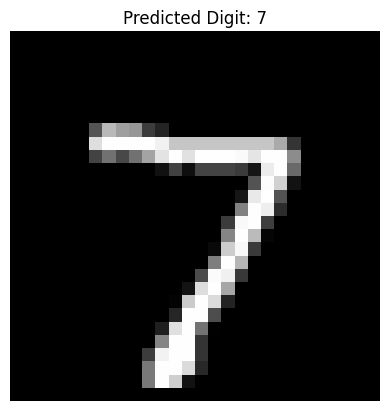

In [1]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

(X_train, Y_train), (X_test, Y_test) = tf.keras.datasets.mnist.load_data()


X_train = X_train / 255.0
X_test = X_test / 255.0


X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)


def create_batchnorm_dropout_cnn():

    model = tf.keras.models.Sequential([


        tf.keras.layers.Conv2D(
            32, (3, 3),
            activation='relu',
            strides=2,
            input_shape=(28, 28, 1)
        ),

        tf.keras.layers.BatchNormalization(),


        tf.keras.layers.Conv2D(
            64, (3, 3),
            activation='relu',
            strides=2
        ),

        tf.keras.layers.BatchNormalization(),


        tf.keras.layers.Flatten(),


        tf.keras.layers.Dense(
            128,
            activation='relu'
        ),

        tf.keras.layers.BatchNormalization(),


        tf.keras.layers.Dropout(0.5),


        tf.keras.layers.Dense(
            10,
            activation='softmax'
        )
    ])


    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model



model = create_batchnorm_dropout_cnn()


model.summary()



history = model.fit(
    X_train,
    Y_train,
    epochs=5,
    batch_size=64,
    validation_data=(X_test, Y_test)
)



test_loss, test_accuracy = model.evaluate(
    X_test, Y_test, verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)


predictions = model.predict(X_test[:1])

predicted_digit = np.argmax(predictions[0])

print("Predicted Digit:", predicted_digit)
print("Actual Digit:", Y_test[0])



plt.imshow(X_test[0].squeeze(), cmap='gray')
plt.title(f"Predicted Digit: {predicted_digit}")
plt.axis('off')
plt.show()
